# Lab No 2: Data Manipulation and Working with Web Services

## 2 Challenges

# Challenge No 1:

1. Using a Dictionary, create a dataframe (table), with at least 4 columns and more than 100 rows. How come you can create this among data from scratch without defining every single row of data? 
2. Using the appropriate method, create a new DataFrame containing only the first 30 rows and the first 3 columns of the original DataFrame. Name this new DataFrame subset_df.
3. Using the appropriate method, filter the rows from the original dataframe where a numerical attribute(column) is greater than a particular numerical value, and find another categorical attribute that is equal to a specific string or text. Name this new DataFrame filtered_df.
4. Check this website https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html and apply the methods, mean, standard deviation, group_by to run fundamental statistical analysis of your created data frame.
5. Make sure you comment on your code and describe how you are manipulating the data.


In [1]:
#1.Using a Dictionary, create a dataframe (table), with at least 4 columns and more than 100 rows.

#Using the example above (in workbook) to help answer this challenge: Create arrays->use a dictionary to create dataframe
#How come you can create this among data from scratch without defining every single row of data?: like in the example it can be done by using range(),np.repeat(),np.randint() functions,np.array() etc.

import numpy as np
import pandas as pd

#To create a dataframe with 4 columns we need to create 4 arrays:
years = range(2010,2018)#from example
a = np.repeat(years,15)#from example - changed repeat from 4 (creates 32 values) to 15 (creates 120 values)
b = np.random.randint(0,40,120)#from example but changed the repeat from 32 values to 120 values to satisfy the 'at least 100 rows' aspect of the challenge
c = np.random.randint(25,75,120)#creating another simple array
building = ['Irvine','Purdie', 'Gateway', 'Buchanan']
d = np.repeat(building,30)#trying the repeat() function with a list instead - repeating 30 times (120 values)

#Create dataframe
e = pd.DataFrame({'a':a,'b':b,'c':c,'d':d}) #using a dictionary
print("First five rows of dataframe created:",e.head())

#should have 4 columns and 120 rows:
print(e.shape)

First five rows of dataframe created:       a   b   c       d
0  2010   1  51  Irvine
1  2010  31  47  Irvine
2  2010  39  60  Irvine
3  2010  36  39  Irvine
4  2010  23  27  Irvine
(120, 4)


In [2]:
#2.Using the appropriate method, create a new DataFrame containing only the first 30 rows and the first 3 columns of the original DataFrame. Name this new DataFrame subset_df.

#using guidance of workbook example, want to extract the first 30 rows and first 3 columns: e.g. using .iloc[row index, column index]->define this as new dataframe
subset_df = e.iloc[0:30,0:3]#0:30 gives first 30 rows and 0:3 gives first 3 columns
subset_df.head()#should return columns a,b,c only and rows 0-4

,a,b,c
0,2010,1,51
1,2010,31,47
2,2010,39,60
3,2010,36,39
4,2010,23,27


In [3]:
#3.Using the appropriate method, filter the rows from the original dataframe where a numerical attribute(column) is greater than a particular numerical value, and find another categorical attribute 
    #that is equal to a specific string or text. Name this new DataFrame filtered_df.

#Filter using loc[row name, column name] (done in lab 1 challenge 8 as well)

#e.g. filter where b>30, d='Irvine'
filtered_df = e.loc[(e['b']>30)&(e['d']=='Irvine')]#using '&' since both filters/conditions need to be met
filtered_df.head()

,a,b,c,d
1,2010,31,47,Irvine
2,2010,39,60,Irvine
3,2010,36,39,Irvine
12,2010,31,63,Irvine
13,2010,37,62,Irvine


In [4]:
#4.Check this website https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html and apply the methods, mean, standard deviation, group_by to run fundamental 
    #statistical analysis of your created data frame.

#Using mean:
print("Mean values:",e.mean(numeric_only=True))
print("\n")

#Using stadard deviation:
print("Standard deviation:",e.std(numeric_only=True))
print("\n")

#Using groupby(): e.g. mean of column b for each building in column d
print("Mean by building:",e.groupby('d')['b'].mean().reset_index())#Added in .reset_index() after doing lab 3 where it says to use this to turn 'd' back into a normal Df column instead of an index

Mean values: a    2013.500000
b      21.241667
c      51.591667
dtype: float64


Standard deviation: a     2.300895
b    12.327462
c    14.281972
dtype: float64


Mean by building:           d          b
0  Buchanan  18.966667
1   Gateway  23.433333
2    Irvine  23.366667
3    Purdie  19.200000


In [5]:
#5.Make sure you comment on your code and describe how you are manipulating the data.

#Notes have been included and all challenge 1 code was written using the examples from lab 1,2,3 workbooks, past challenge answers and the website provided :)

## Description: 

Each code cell should have comments that describe what the code is doing, any issues or barriers, citations, and other relevant information. Additionally, use markdown cells where you explain the problem you are addressing and how you did it (here, you can add screenshots of the final outcomes). Some challenges only require you to answer questions and provide insights. This will help the marker evaluate your understanding of the code, the outcomes, and the  problem you have solved.

# Challenge No 2:

**Part No 1:**

1. Using the same workflow previously described, now calculate the clustered areas for the GeoPandasDataFrame `gdf_bikes_end`
2. Make sure you don't have any NaN in your columns, add a CRS, clean up the unnecessary attributes, calculate the cluster values, and plot a map of 4 calculated clusters for the return locations.

**Part No 2:**

1. Using the Glasglow Open Data API ( Transit) https://developer.glasgow.gov.uk/api-details#api=traffic&operation=traffic-sensor-locations fetch all the sensor locations in the city.
2. Map the sensor
3. Find the WorkingZones and Calculate/Map the areas with more and fewer sensors distributed in the city.
4. You will need:
   * Get two separate Geopandas DataFrames, one for the traffic sensors and another one for the WorkingZones.
   * Using `sJoin` ( Spatial Join) https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html
   calculate the overlay of sensors and polygons.
   * Using group_by https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html to count the number of sensors per WorkingZone
   * Make sure you add the counts into the WorkingZone polygons of Glasgow so you can create a map of Zones with more and fewer traffic sensors.
   * Of course, you will need extra steps where you manipulate the data and extract what you need, for instance, clipping the Working Zones only for Glasgow.
5. Make sure you comment on your code and describe how you are manipulating the data.

In [6]:
#Part 1: Same workflow but for gdf_bikes_end
import requests
import pandas as pd
import geopandas as gpd

# Let's describe the url, it is usually easier to do it like this, so in the future, you can easily update the URL
url_bikes = "https://api.glasgow.gov.uk/mobility/v1/get_rentals?startDate=2022-05-01&endDate=2023-05-01"
# Making the query to the web server, using the Get method from the requests library 
response = requests.get(url_bikes)
response

<Response [200]>

In [7]:
#Now we get the response from the web server, we need to translate that into a format we can manipulate, like JSON.
data = response.json()
data
# careful here you will get a huge outcome; explore what you get, and then you can clear this cell outcome

# Usually, there are two labels into the web server response the metadata, and the data; we will use the data label
# to get all attributes included. 
rental_data = data['data']
rental_data
# See the structure of the data, you can see
# 'attribute':'value' structure
# each {} define one row or one element
# Again, here you will get a huge outcome; just explore what you get, and then you can clear this cell outcome

rental_pd = pd.DataFrame(rental_data)
#Can you guess what we are doing here?
rental_pd.head()
rental_pd.shape
rental_pd.columns

Index(['created', 'updated', 'cityId', 'bikeId', 'startDate', 'startPlaceId',
       'startPlaceCityId', 'startPlaceName', 'startPlaceStationNumber',
       'startPlaceLat', 'startPlaceLong', 'startChannelId', 'endDate',
       'endPlaceId', 'endPlaceCityId', 'endChannelId', 'endPlaceName',
       'endPlaceStationNumber', 'endPlaceLat', 'endPlaceLong',
       'durationSeconds', 'isInvalid', 'price', 'isEbike'],
      dtype='object')

In [8]:
# Check for NaN in the coordinates column
nan_in_column_Lat = rental_pd['endPlaceLat'].isna().any()
nan_in_column_Long = rental_pd['endPlaceLong'].isna().any()

print(nan_in_column_Lat,nan_in_column_Long)

# Alternatively, you can use the following to count NaN values
nan_in_column_Lat = rental_pd['endPlaceLat'].isna().sum()
nan_in_column_Long = rental_pd['endPlaceLong'].isna().sum()
print(nan_in_column_Lat,nan_in_column_Long)

True True
33 33


In [9]:
clean_rental_pd = rental_pd.dropna(subset=['startPlaceLat', 'startPlaceLong','endPlaceLat','endPlaceLong'])
clean_rental_pd.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9940 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   created                  9940 non-null   object 
 1   updated                  9940 non-null   object 
 2   cityId                   9940 non-null   object 
 3   bikeId                   9940 non-null   object 
 4   startDate                9940 non-null   object 
 5   startPlaceId             9940 non-null   object 
 6   startPlaceCityId         9940 non-null   object 
 7   startPlaceName           9940 non-null   object 
 8   startPlaceStationNumber  9555 non-null   float64
 9   startPlaceLat            9940 non-null   float64
 10  startPlaceLong           9940 non-null   float64
 11  startChannelId           0 non-null      object 
 12  endDate                  9940 non-null   object 
 13  endPlaceId               9940 non-null   object 
 14  endPlaceCityId           9940

In [10]:
gdf_bikes_end = gpd.GeoDataFrame(clean_rental_pd, geometry=gpd.points_from_xy(clean_rental_pd['endPlaceLong'], clean_rental_pd['endPlaceLat']))

# Print the GeoDataFrame
gdf_bikes_end.info()
# Do we need all those columns? And you see, there is also a lot of pre-processing to do with all the object Dtype

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 9940 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   created                  9940 non-null   object  
 1   updated                  9940 non-null   object  
 2   cityId                   9940 non-null   object  
 3   bikeId                   9940 non-null   object  
 4   startDate                9940 non-null   object  
 5   startPlaceId             9940 non-null   object  
 6   startPlaceCityId         9940 non-null   object  
 7   startPlaceName           9940 non-null   object  
 8   startPlaceStationNumber  9555 non-null   float64 
 9   startPlaceLat            9940 non-null   float64 
 10  startPlaceLong           9940 non-null   float64 
 11  startChannelId           0 non-null      object  
 12  endDate                  9940 non-null   object  
 13  endPlaceId               9940 non-null   object  
 14  endPl

In [11]:
gdf_bikes_end.crs
gdf_bikes_end = gdf_bikes_end.set_crs("EPSG:4326")

In [12]:
gdf_bikes_end.explore()

In [13]:
gdf_bikes_end.dtypes
keep_cols = [
    "endDate",
    "endPlaceId",
    "endPlaceName",
    "durationSeconds",
    "isInvalid",
    "price",
    "isEbike",
    "endPlaceLat",
    "endPlaceLong",
    "geometry",
]
gdf_bikes_end = gdf_bikes_end[keep_cols]
gdf_bikes_end.head()
gdf_bikes_end.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 9940 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   endDate          9940 non-null   object  
 1   endPlaceId       9940 non-null   object  
 2   endPlaceName     9940 non-null   object  
 3   durationSeconds  9940 non-null   int64   
 4   isInvalid        9940 non-null   bool    
 5   price            9940 non-null   float64 
 6   isEbike          9940 non-null   bool    
 7   endPlaceLat      9940 non-null   float64 
 8   endPlaceLong     9940 non-null   float64 
 9   geometry         9940 non-null   geometry
dtypes: bool(2), float64(3), geometry(1), int64(1), object(3)
memory usage: 718.3+ KB


In [14]:
gdf_bikes_end.endPlaceId = gdf_bikes_end.endPlaceId.astype(int)
gdf_bikes_end.endPlaceName = gdf_bikes_end.endPlaceName.astype(str)
gdf_bikes_end['endDate'] = pd.to_datetime(gdf_bikes_end['endDate'], format='%Y-%m-%dT%H:%M:%SZ')

gdf_bikes_end.dtypes
#gdf_bikes_end['endPlaceName'].unique()

gdf_bikes_end.head()

,endDate,endPlaceId,endPlaceName,durationSeconds,isInvalid,price,isEbike,endPlaceLat,endPlaceLong,geometry
0,2022-05-01 00:02:36,264299,ELECTRIC - Broomielaw,56,False,2.0,True,55.856600,-4.263521,POINT (-4.26352 55.85660)
1,2022-05-01 00:22:34,3812776,Alexandra Park (south entrance) Alexandra Para...,1097,False,1.0,False,55.863128,-4.210282,POINT (-4.21028 55.86313)
2,2022-05-01 00:10:08,264302,Botanic Gardens - ELECTRIC,344,False,1.0,False,55.878278,-4.288487,POINT (-4.28849 55.87828)
3,2022-05-01 02:57:49,349455,ELECTRIC - Cessnock Subway Station,10400,False,6.0,False,55.851918,-4.294490,POINT (-4.29449 55.85192)
4,2022-05-01 01:21:31,264295,ELECTRIC - St Enoch Square,4611,False,3.0,False,55.856829,-4.255292,POINT (-4.25529 55.85683)


In [15]:
from sklearn.cluster import KMeans
num_clusters = 4

kmeans_return = KMeans(n_clusters=num_clusters, random_state=42)
gdf_bikes_end['kmeans_cluster'] = kmeans_return.fit_predict(gdf_bikes_end[['endPlaceLong', 'endPlaceLat']])

gdf_bikes_end.head()

C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,endDate,endPlaceId,endPlaceName,durationSeconds,isInvalid,price,isEbike,endPlaceLat,endPlaceLong,geometry,kmeans_cluster
0,2022-05-01 00:02:36,264299,ELECTRIC - Broomielaw,56,False,2.0,True,55.856600,-4.263521,POINT (-4.26352 55.85660),3
1,2022-05-01 00:22:34,3812776,Alexandra Park (south entrance) Alexandra Para...,1097,False,1.0,False,55.863128,-4.210282,POINT (-4.21028 55.86313),0
2,2022-05-01 00:10:08,264302,Botanic Gardens - ELECTRIC,344,False,1.0,False,55.878278,-4.288487,POINT (-4.28849 55.87828),1
3,2022-05-01 02:57:49,349455,ELECTRIC - Cessnock Subway Station,10400,False,6.0,False,55.851918,-4.294490,POINT (-4.29449 55.85192),1
4,2022-05-01 01:21:31,264295,ELECTRIC - St Enoch Square,4611,False,3.0,False,55.856829,-4.255292,POINT (-4.25529 55.85683),3


In [16]:
import leafmap

m = leafmap.Map(center=(55.860166, -4.257505),
                zoom=12,
                draw_control=False,
                measure_control=False,
                fullscreen_control=False,
                attribution_control=True,
                   
               )

m.add_basemap("OpenStreetMap")
m.add_data(
    gdf_bikes_end,
    column='kmeans_cluster',
    legend_title='Clusters',
    cmap='Set1',
    k=4,
)

#Ploting the map
m

OpenStreetMap has been already added before.


Map(center=[55.860166, -4.257505], controls=(AttributionControl(options=['position', 'prefix'], position='bott…

<Axes: >

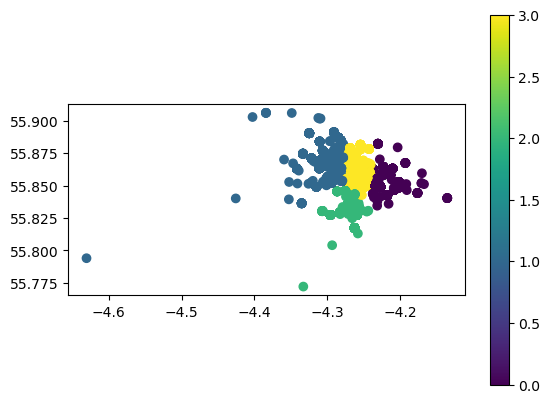

In [17]:
#Whilst leafmap is having a seizure - i'm just checking using a simple .plot() really quick
gdf_bikes_end.plot(column='kmeans_cluster', legend=True)

In [18]:
#Part 2:Using the Glasglow Open Data API ( Transit) https://developer.glasgow.gov.uk/api-details#api=traffic&operation=traffic-sensor-locations fetch all the sensor locations in the city.
    #Map the sensor
    #Find the WorkingZones and Calculate/Map the areas with more and fewer sensors distributed in the city.
    #You will need:
    #Get two separate Geopandas DataFrames, one for the traffic sensors and another one for the WorkingZones.
    #Using sJoin ( Spatial Join) https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html calculate the overlay of sensors and polygons.
    #Using group_by https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html to count the number of sensors per WorkingZone
    #Make sure you add the counts into the WorkingZone polygons of Glasgow so you can create a map of Zones with more and fewer traffic sensors.
    #Of course, you will need extra steps where you manipulate the data and extract what you need, for instance, clipping the Working Zones only for Glasgow.

#So workflow summary: get traffic sensor+working zones then use gpd.sjoin() to do a sptial join and find which traffic sensors fall into which polygon, use .groupby().size() to find number of
    #sensors in each zone,then use .merge() function to add number of sensors to each working zone, then make map to show quantity of sensors in each area?

In [19]:
import requests
import pandas as pd
import geopandas as gpd

In [20]:
# Let's describe the url, it is usually easier to do it like this, so in the future, you can easily update the URL
sensors = "https://api.glasgow.gov.uk/traffic/v1/movement/sites"
# Making the query to the web server, using the Get method from the requests library 
response = requests.get(sensors)
response
data = response.json()
data

[{'siteId': 'GH020A_B',
  'from': {'description': 'Gallowgate west to Sword St',
   'lat': '55.8543754827825',
   'long': '-4.217259197086495'},
  'to': {'description': 'Gallowgate west to Sword St',
   'lat': '55.854434529999814',
   'long': '-4.216974959509279'}},
 {'siteId': 'GJ3301_D',
  'from': {'description': 'Carmunnock Rd southbound',
   'lat': '55.821736212748405',
   'long': '-4.2561270616272875'},
  'to': {'description': 'Carmunnock Rd southbound',
   'lat': '55.82105417976632',
   'long': '-4.25607160697339'}},
 {'siteId': 'GH020A_A',
  'from': {'description': 'Gallowgate east to Sword St',
   'lat': '55.85539015389372',
   'long': '-4.225769520669405'},
  'to': {'description': 'Gallowgate east to Sword St',
   'lat': '55.85526881737797',
   'long': '-4.2260182328994995'}},
 {'siteId': 'GJ3301_C',
  'from': {'description': 'Carmunnock Rd northbound to Kings Park Avenue',
   'lat': '55.81925458152306',
   'long': '-4.255696036412074'},
  'to': {'description': 'Carmunnock Rd 

In [21]:
# empty lists to store what we need
site_ids = []
from_lats = []
from_longs = []
from_descriptions = []

# Iterate over each entry in the JSON array
for entry in data:
    site_id = entry['siteId']
    from_description = entry['from']['description']
    from_lat = entry['from']['lat']
    from_long = entry['from']['long']
    
    # Append values to lists
    site_ids.append(site_id)
    from_descriptions.append(from_description)
    from_lats.append(from_lat)
    from_longs.append(from_long)
    
# Create a Pandas DataFrame, using the lists.
df = pd.DataFrame({
    'siteId': site_ids,
    'from_description': from_descriptions,
    'from_lat': from_lats,
    'from_long': from_longs,
})

In [22]:
df.head()

,siteId,from_description,from_lat,from_long
0,GH020A_B,Gallowgate west to Sword St,55.8543754827825,-4.217259197086495
1,GJ3301_D,Carmunnock Rd southbound,55.821736212748405,-4.2561270616272875
2,GH020A_A,Gallowgate east to Sword St,55.85539015389372,-4.225769520669405
3,GJ3301_C,Carmunnock Rd northbound to Kings Park Avenue,55.81925458152306,-4.255696036412074
4,GJ3301_B,Kings Park Ave westbound to Carmunnock Rd,55.820288451422314,-4.250775113480551


In [23]:
#Please refer to later code and comments to understand the thought process behind this code cell
#Essentially 4 siteIds need to_lat and to_long instead of their from_lat and from_long so just replacing that now using .loc and .append()
#got this code by adapting what we've done in the labs
    #aka finding the specific sites then setting the (from_lat,from_long)=(to_lat,to_long)
df.loc[df['siteId']=='GE0501_F',['from_lat','from_long']]=[55.87820129979653,-4.242535262203058]
df.loc[df['siteId']=='GD0971_C',['from_lat','from_long']]=[55.87054393290359,-4.299990352159061]
df.loc[df['siteId']=='GA4851_R',['from_lat','from_long']]=[55.85741063079249, -4.249086854965875]
df.loc[df['siteId']=='GA4701_C',['from_lat','from_long']]=[55.85459359919607, -4.250777504302567]
df.loc[df['siteId']=='GG1171_C',['from_lat','from_long']]=[55.8713589959702, -4.15929168603979]

In [24]:
gdf_sensors = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['from_long'], df['from_lat']), crs='EPSG:4326')
gdf_sensors.head()

,siteId,from_description,from_lat,from_long,geometry
0,GH020A_B,Gallowgate west to Sword St,55.8543754827825,-4.217259197086495,POINT (-4.21726 55.85438)
1,GJ3301_D,Carmunnock Rd southbound,55.821736212748405,-4.2561270616272875,POINT (-4.25613 55.82174)
2,GH020A_A,Gallowgate east to Sword St,55.85539015389372,-4.225769520669405,POINT (-4.22577 55.85539)
3,GJ3301_C,Carmunnock Rd northbound to Kings Park Avenue,55.81925458152306,-4.255696036412074,POINT (-4.25570 55.81925)
4,GJ3301_B,Kings Park Ave westbound to Carmunnock Rd,55.820288451422314,-4.250775113480551,POINT (-4.25078 55.82029)


In [25]:
#Doing a simple .explore() to see where the individual sensor locations are:
gdf_sensors.explore()

In [26]:
#Looking at the .explore() map, i can see a point which has been plotted near Lagos and hovering over that point i can see that it 
    #has from_lat=from_long=0 with siteID=GG180A_A and from_description as Westerhouse Road which should be in Glasgow

#checking that siteID again to double check:
print(gdf_sensors.loc[gdf_sensors['siteId']=='GG180A_A'])#confirms it does have 0 geometry and is not a .explore() issue

#next checking if there are any other 0 lat/long points:
#then tried this: gdf_sensors.loc[(gdf_sensors['from_lat']==0)| (gdf_sensors['from_long']==0)] 
    #but this returned nothing so i suspect from_lat and from_long are currently objects
gdf_sensors.dtypes #they are indeed currently objects

#converting the coord columns into floats:
gdf_sensors['from_lat'] = gdf_sensors['from_lat'].astype(float)
gdf_sensors['from_long'] = gdf_sensors['from_long'].astype(float)
gdf_sensors.dtypes

#then checking again if any other lat/long points with zero :
gdf_sensors.loc[(gdf_sensors['from_lat']==0)| (gdf_sensors['from_long']==0)] #returned 65 rows which feels a bit high
#so trying & not | (or):
gdf_sensors.loc[(gdf_sensors['from_lat']==0)& (gdf_sensors['from_long']==0)] # still returned 65 rows

#Thinking if it was because the coordinates were stored in to_lat and to_long so were excluded when creating the df using defined lists
#testing this theory with the inital issue area GG180A_A - using the logic from the lecturer's code:
    #basically finding the inital full output for location GG180A_A and inspecting the to_lat and to_long
for entry in data:
    if entry['siteId']=='GG180A_A':
        print(entry)
#Since to to_lat and to_long are both 0 i think its fine to assume that all the (0,0) geometry entries are from an incomplete API?
#Hence i'm just goin to remove all (0,0) entries so that they can stop skewing the .explore() plot:
    #so want to exclude every entry that has a lat of 0 and a long of 0:
gdf_sensors=gdf_sensors.loc[(gdf_sensors['from_lat']!=0)&(gdf_sensors['from_long']!=0)]
gdf_sensors.shape #which is (1210,5) which confirms my theory that all the 65 rows of (0,0) also had o to_lat and to_long

        siteId      from_description from_lat from_long  \
1235  GG180A_A  Westerhouse Road n/b        0         0   

                     geometry  
1235  POINT (0.00000 0.00000)  
{'siteId': 'GG180A_A', 'from': {'description': 'Westerhouse Road n/b', 'lat': '0', 'long': '0'}, 'to': {'description': 'Westerhouse Road n/b', 'lat': '0', 'long': '0'}}


(1210, 5)

In [27]:
#This code cell was before i changed the 5 (from_lat,from_long) to (to_lat,to_long)


#Now it seems that there are some plots in Wales: namely GD0971_C,GA4851_R,GA4701_C,GE0501_F,GG1171_C
#want to inspect the coordinates of these locations:
print(gdf_sensors.loc[gdf_sensors['siteId']=='GD0971_C'])
print(gdf_sensors.loc[gdf_sensors['siteId']=='GA4851_R'])
print(gdf_sensors.loc[gdf_sensors['siteId']=='GA4701_C'])
print(gdf_sensors.loc[gdf_sensors['siteId']=='GE0501_F'])
print(gdf_sensors.loc[gdf_sensors['siteId']=='GG1171_C'])

#then using the same method as i did earlier to compare this to the raw api output- since the geometry isn't (0,0) i have a feeling 
    #these are the coordinates in which the to_lat and to_long do matter
for entry in data:
    if entry['siteId'] in ['GD0971_C','GA4851_R','GA4701_C','GE0501_F','GG1171_C']:
        print(entry)
#from this you can see that the coordinates from the json with to_lat and to_long do have coordinates which lie within glasgow so
    #so I'm going to go back to before we formed the gdf to use .append() on these locations using .loc

       siteId                    from_description   from_lat  from_long  \
644  GD0971_C  Byres Road northbound to Church St  55.870544   -4.29999   

                      geometry  
644  POINT (-4.29999 55.87054)  
       siteId    from_description   from_lat  from_long  \
891  GA4851_R  Trongate Eastbound  55.857411  -4.249087   

                      geometry  
891  POINT (-4.24909 55.85741)  
        siteId             from_description   from_lat  from_long  \
1177  GA4701_C  Stockwell Street Northbound  55.854594  -4.250778   

                       geometry  
1177  POINT (-4.25078 55.85459)  
       siteId              from_description   from_lat  from_long  \
379  GE0501_F  Keppochhill Road (westbound)  55.878201  -4.242535   

                      geometry  
379  POINT (-4.24254 55.87820)  
       siteId from_description   from_lat  from_long  \
170  GG1171_C      Stepps Road  55.871359  -4.159292   

                      geometry  
170  POINT (-4.15929 55.87136)  
{'siteI

In [28]:
#Now after that the gdf_sensors.explore() should only include points in Glasgow:
gdf_sensors.explore()

In [29]:
#Creating the second geodataframe for the WorkingZones and inspecting its attributes before anything else
gdf_working_zones = gpd.read_file("data/WorkplaceZones2011Scotland.shp")

print(gdf_working_zones.info(),"\n",gdf_working_zones.columns,"\n",gdf_working_zones.crs,"\n",gdf_working_zones.head())

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5375 entries, 0 to 5374
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   LADCD     5375 non-null   object  
 1   WZCD      5375 non-null   object  
 2   geometry  5375 non-null   geometry
dtypes: geometry(1), object(2)
memory usage: 126.1+ KB
None 
 Index(['LADCD', 'WZCD', 'geometry'], dtype='object') 
 EPSG:27700 
        LADCD       WZCD                                           geometry
0  S12000040  S34005373  POLYGON ((304339.365 666492.616, 304341.959 66...
1  S12000033  S34000001  POLYGON ((393511.570 805880.709, 393506.643 80...
2  S12000033  S34000002  POLYGON ((393557.291 806046.379, 393563.505 80...
3  S12000033  S34000003  POLYGON ((394178.803 806251.348, 394195.604 80...
4  S12000033  S34000004  POLYGON ((394179.722 806307.033, 394181.625 80...


In [30]:
#Note that after searching up the Glasgow LADCD it has now been updated to S12000049 after 2019 but since this data is from 2011 th LADCD was still S12000046
#checked this by doing:
    #gdf_working_zones[gdf_working_zones['LADCD']=='S12000049'].shape which gave (0, 3) 
    #then repeating for S12000046 which gave(639, 3) which confirmed that Glasgow had not yet been changed to S12000049 when this data was published
gdf_working_zones[gdf_working_zones['LADCD']=='S12000046'].shape

(639, 3)

In [31]:
#First want to remove any data that is from outside Glasgow by creating a new subset:
glasgow_working_zones = gdf_working_zones[gdf_working_zones['LADCD']=='S12000046']
glasgow_working_zones.info()
glasgow_working_zones.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 639 entries, 486 to 5368
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   LADCD     639 non-null    object  
 1   WZCD      639 non-null    object  
 2   geometry  639 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 20.0+ KB


,LADCD,WZCD,geometry
486,S12000046,S34000364,"POLYGON ((257379.622 666207.822, 257401.701 66..."
487,S12000046,S34000365,"POLYGON ((257949.719 666169.840, 257952.285 66..."
488,S12000046,S34000366,"POLYGON ((257507.317 666045.911, 257510.217 66..."
489,S12000046,S34000367,"POLYGON ((258726.396 665008.801, 258699.145 66..."
490,S12000046,S34000368,"POLYGON ((258541.321 665418.943, 258536.495 66..."


In [32]:
#Quickly doing a last check to see if there are any na values or if any dtypes are different from what we would expect:
print("Dtypes: Sensor:",gdf_sensors.dtypes,"\n glasgow working zones:", glasgow_working_zones.dtypes)
print("Any na values from sensor data:",gdf_sensors['from_lat'].isna().sum(),gdf_sensors['from_long'].isna().sum())
print("Any missing zone ids from glasgow_working_zones:",glasgow_working_zones['WZCD'].isna().sum())
print("Any missing geometries:",gdf_sensors['geometry'].isna().sum(),glasgow_working_zones['geometry'].isna().sum())

Dtypes: Sensor: siteId                object
from_description      object
from_lat             float64
from_long            float64
geometry            geometry
dtype: object 
 glasgow working zones: LADCD         object
WZCD          object
geometry    geometry
dtype: object
Any na values from sensor data: 0 0
Any missing zone ids from glasgow_working_zones: 0
Any missing geometries: 0 0


In [33]:
#Next is checking the crs to see if the two geodataframe crs matches or not:
glasgow_working_zones.crs#EPSG:27700 (eastings/northings)
gdf_sensors.crs#is WGS 84

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [34]:
#Since the crs is different for both geodataframes,nees to convert one, probably easier to convert sensor to 27700 since its points not polygons, this is fine to do for .explore() but if i was using folium i would change this to WGS 84
gdf_sensors = gdf_sensors.to_crs(glasgow_working_zones.crs) #came back to edit this after completing lab 3 where we used .to_crs() and i though this would be more fitting
gdf_sensors.crs

<Projected CRS: EPSG:27700>
Name: OSGB36 / British National Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: United Kingdom (UK) - offshore to boundary of UKCS within 49°45'N to 61°N and 9°W to 2°E; onshore Great Britain (England, Wales and Scotland). Isle of Man onshore.
- bounds: (-9.01, 49.75, 2.01, 61.01)
Coordinate Operation:
- name: British National Grid
- method: Transverse Mercator
Datum: Ordnance Survey of Great Britain 1936
- Ellipsoid: Airy 1830
- Prime Meridian: Greenwich

In [35]:
#Now that everything matches and there aren't any other gaps in the data that i can find - it is time to do the spatial join!
#(done using the san fransico example as a basis - from lab 2)
sensors_zones=gpd.sjoin(gdf_sensors,glasgow_working_zones,how='inner')
sensors_zones.head()
sensors_zones.shape
sensors_zones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 1206 entries, 0 to 1274
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   siteId            1206 non-null   object  
 1   from_description  1206 non-null   object  
 2   from_lat          1206 non-null   float64 
 3   from_long         1206 non-null   float64 
 4   geometry          1206 non-null   geometry
 5   index_right       1206 non-null   int64   
 6   LADCD             1206 non-null   object  
 7   WZCD              1206 non-null   object  
dtypes: float64(2), geometry(1), int64(1), object(4)
memory usage: 84.8+ KB


In [36]:
#Next is to use the .group_by() function to calculate the number of sensors in each working zone
#So: group each sensor by WZCD then find how many there are in each zone

#came back to edit this after lab 3 since we used this as an example which i thought was more efficient:spatial_result.groupby('buffer_id').size().reset_index(name='listings_per_buffer') so used this layout instead for this
sensor_counts = sensors_zones.groupby('WZCD').size().reset_index(name='sensor_count')
sensor_counts.head()
sensor_counts.shape
sensor_counts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   WZCD          338 non-null    object
 1   sensor_count  338 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 5.4+ KB


In [37]:
#Next to do is to merge the sensor counts with the glasgow working zones using the shared WZCD column so that a map can be made
    #used the example using the san fransico data again as a basis
#First did zones_counts_merge=pd.merge(glasgow_working_zones,sensor_counts,on='WZCD') but then the shape was (337,4) rather than the expected (639,4) because the merge had removed any zone 
    #without any sensor counts (aka NaN), so to fix this i tried using how='left' which we discussed in class and this gave me the expected shape again, because a left join would keep all the rows from
    #glasgow_working_zones rather than defualting to an inner join and removing that data
    #also used this website to help with this issue:https://geopandas.org/en/stable/docs/user_guide/mergingdata.html
zones_counts_merge=pd.merge(glasgow_working_zones,sensor_counts,on='WZCD',how='left')
zones_counts_merge.shape
zones_counts_merge.head()
zones_counts_merge.shape
print("Minimum sensor count:",zones_counts_merge['sensor_count'].min())
print("Maximum sensor count:",zones_counts_merge['sensor_count'].max())

Minimum sensor count: 1.0
Maximum sensor count: 25.0


In [38]:
#Since the zones with no sensor data is showing up as NaN rather than 0, need to fix that so that we can map the data which includes all the fewer counts (including 0)
print(zones_counts_merge['sensor_count'].isna().sum())

301


In [39]:
#use .loc to find the NaN values then replace them with the value 0:
zones_counts_merge.loc[zones_counts_merge['sensor_count'].isna(),'sensor_count']=0 #could use .fillna() but wanted to see if i could do it only using lab taught code :)
#check to see if there are any NaN values left in sensor_count column:
print(zones_counts_merge['sensor_count'].isna().sum())
zones_counts_merge.head()

0


,LADCD,WZCD,geometry,sensor_count
0,S12000046,S34000364,"POLYGON ((257379.622 666207.822, 257401.701 66...",0.0
1,S12000046,S34000365,"POLYGON ((257949.719 666169.840, 257952.285 66...",1.0
2,S12000046,S34000366,"POLYGON ((257507.317 666045.911, 257510.217 66...",0.0
3,S12000046,S34000367,"POLYGON ((258726.396 665008.801, 258699.145 66...",5.0
4,S12000046,S34000368,"POLYGON ((258541.321 665418.943, 258536.495 66...",2.0


In [40]:
#Double checking that all 639 zones are still in the dataset and that the sensor count still matches 1206 from earlier:
print("Glasgow_workplace_zones:",zones_counts_merge.shape)
print("Total sensor records:",zones_counts_merge['sensor_count'].sum())

Glasgow_workplace_zones: (639, 4)
Total sensor records: 1206.0


<Axes: >

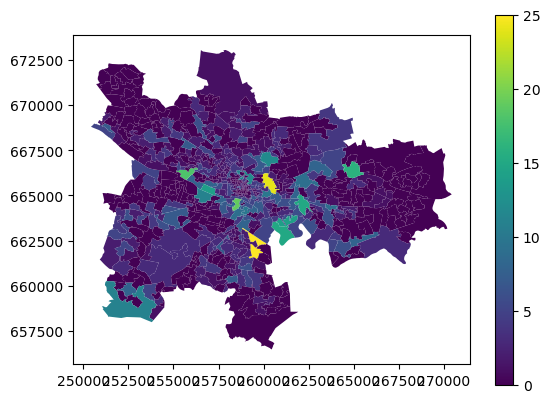

In [41]:
#making the map to show the quantity of traffic sensor records in each Glasgow workspace zone 
#using .plot() with column=sensor_count and a legend:
zones_counts_merge.plot(column='sensor_count',legend=True)

In [42]:
zones_counts_merge.explore(column='sensor_count', cmap='Oranges')

## Description: 

Each code cell should have comments that describe what the code is doing, any issues or barriers, citations, and other relevant information. Additionally, use markdown cells where you explain the problem you are addressing and how you did it (here, you can add screenshots of the final outcomes). Some challenges only require you to answer questions and provide insights. This will help the marker evaluate your understanding of the code, the outcomes, and the  problem you have solved.